## Context

From [[duck_cup_v001_v010]] we know the model conditions duck-grabbing on cup position — a spurious correlation from fixed cup placement in training data. We're adding cup variation to the dataset, but we want to understand if image masking can serve as additional regularization to improve generalizability.

Two ideas on the table:
1. **Image masking** — mask regions of raw images before the frozen SigLIP encoder. Removes spatial info entirely, but encoder never saw masked images during pretraining → OOD risk.
2. **Embedding dropout** — drop random dimensions after the encoder. Clean regularization, but cup info is distributed across dimensions → might not break the correlation.

My hypothesis: image masking is stronger because it fully excludes objects spatially, where dropout never clears semantic information from distributed embeddings. But we need to prove this.

## Research Goal

**Evaluate if masked images can be blended into SmolVLA training data to improve generalizability, without producing OOD embeddings that are useless at inference.**

## Questions

1. Are masked image embeddings in-distribution for the frozen SigLIP encoder, or do they land in a different manifold?
2. What masking strategies preserve task-relevant features (duck, gripper) while suppressing spurious ones (cup position, background)?
3. What masking ratio is the sweet spot — too aggressive kills duck signal, too light keeps cup signal?
4. Does each camera need a different strategy? Wrist cam sees duck/gripper — masking there might hurt. Top/side cams see full scene including cup — that's where we want to break the correlation.

## Experiment Plan

### Exp 1 — Collect Embeddings

### Exp 2 — UMAP / Distribution Analysis

### Exp 3 — Feature Attribution

---

### Exp 4 — Inference Sanity Check

Run best v010 checkpoint (015k-035k range) with masked inputs at inference time:
- Measure success rate degradation curve as masking intensity increases
- Smooth degradation → encoder handles it, masking during training viable
- Cliff drop → encoder produces garbage, masking won't work as regularization

### Exp 5 — Compare to Embedding Dropout Baseline

- Same v010 checkpoint, add dropout (0.1, 0.2, 0.3) on embeddings at inference
- Compare degradation curve to image masking
- This gives us the direct comparison: which regularization degrades more gracefully?

## Success Criteria

- [ ] Masked embeddings overlap with clean embeddings in UMAP (not separate cluster)
- [ ] At least one masking strategy shows smooth degradation in inference, not cliff
- [ ] We identify which cameras tolerate masking and which don't
- [ ] We have a concrete masking config to test in the next training run


### Exp 1 — Collect Embeddings

Run frozen SigLIP on images from 03-merged dataset under different conditions:
- Clean (no mask)
- Gaussian noise mask (varying sigma)
- Circular center mask (varying radius)
- Random rectangular patch cutout (varying count and size)
- Cup-region mask (segment cup, mask it specifically)

Store embeddings per camera, per condition. ~50 episodes should be enough for analysis.

#### Load Dataset

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from lerobot.datasets.lerobot_dataset import LeRobotDataset

REPO_ID = "eternalmay33/01_02_black_merged"
CAMERAS = ["top", "left", "right", "gripper"]

dataset = LeRobotDataset(REPO_ID)
print(f"Dataset: {REPO_ID}")
print(f"Episodes: {dataset.meta.total_episodes}, Frames: {dataset.meta.total_frames}")
print(f"Features: {list(dataset.meta.features.keys())}")

# Load a sample frame
sample = dataset[0]
print(f"\nSample keys: {list(sample.keys())}")
for cam in CAMERAS:
    key = f"observation.images.{cam}"
    if key in sample:
        img = sample[key]
        print(f"  {cam}: {img.shape}, dtype={img.dtype}, range=[{img.min():.2f}, {img.max():.2f}]")

Dataset: eternalmay33/01_02_black_merged
Episodes: 144, Frames: 89932
Features: ['action', 'observation.state', 'observation.images.top', 'observation.images.left', 'observation.images.right', 'observation.images.gripper', 'timestamp', 'frame_index', 'episode_index', 'index', 'task_index']

Sample keys: ['observation.images.top', 'observation.images.left', 'observation.images.right', 'observation.images.gripper', 'action', 'observation.state', 'timestamp', 'frame_index', 'episode_index', 'index', 'task_index', 'task']
  top: torch.Size([3, 480, 640]), dtype=torch.float32, range=[0.05, 1.00]
  left: torch.Size([3, 480, 640]), dtype=torch.float32, range=[0.04, 1.00]
  right: torch.Size([3, 480, 640]), dtype=torch.float32, range=[0.06, 1.00]
  gripper: torch.Size([3, 480, 640]), dtype=torch.float32, range=[0.00, 0.64]


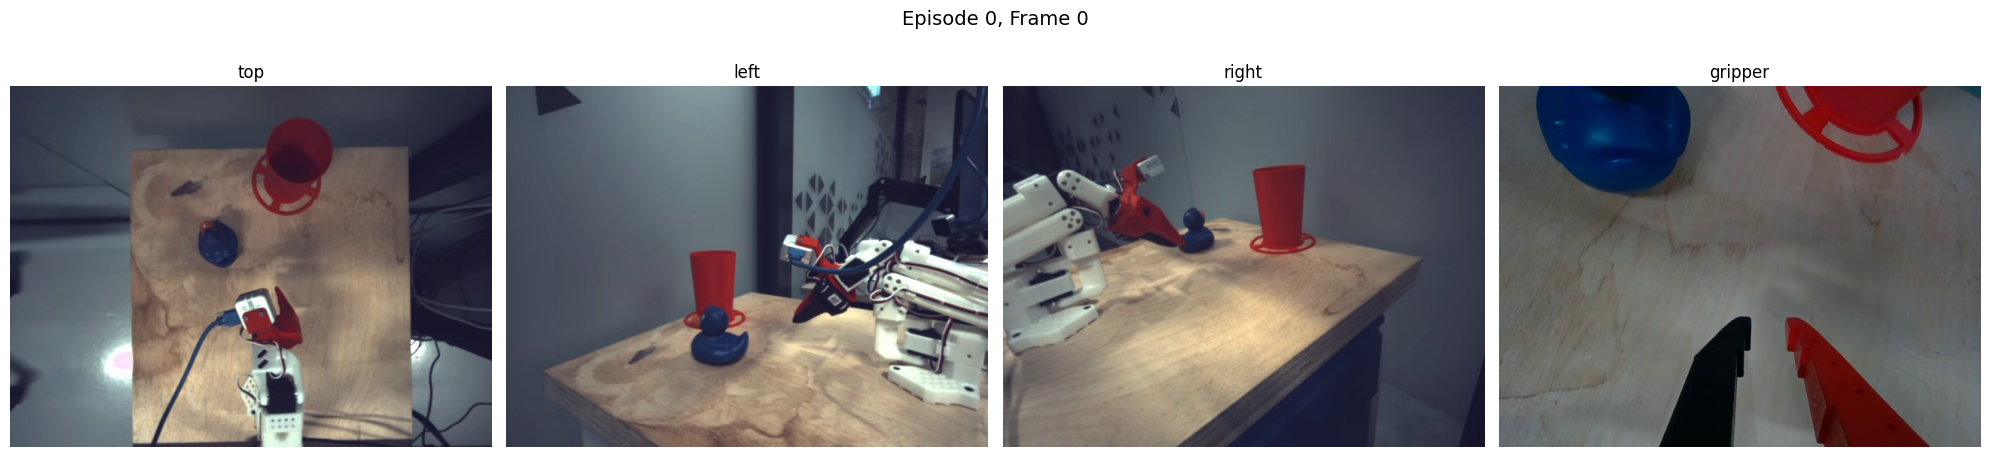

In [2]:
def show_images(images: dict[str, torch.Tensor], title: str = "", figsize_per_img: float = 5):
    """Show camera images side by side.
    
    Args:
        images: {camera_name: (C, H, W) float tensor [0,1]}
        title: figure title
    """
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(figsize_per_img * n, figsize_per_img))
    if n == 1:
        axes = [axes]
    for ax, (name, img) in zip(axes, images.items()):
        ax.imshow(img.permute(1, 2, 0).clamp(0, 1).numpy())
        ax.set_title(name)
        ax.axis("off")
    if title:
        plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

# Test it
imgs = {cam: sample[f"observation.images.{cam}"] for cam in CAMERAS}
show_images(imgs, "Episode 0, Frame 0")

#### Masking strategies — prior work

Most VLAs (RT-2, OpenVLA, SmolVLA, GR00T) **don't mask at all** — they rely on frozen vision encoders with minimal augmentation (random crop + color jitter at most).

**Relevant references:**
- **MaskDP** (Ke et al., CoRL 2024 workshop) — random rectangular masks on diffusion policy inputs. Showed improved generalization to novel object positions. Closest to our use case.
- **MAE probing studies** (He et al., Assran et al.) — SigLIP/DINOv2 tolerate ~30% random patch masking with minimal quality loss, but cliff-drop past 50%. Gives us a concrete ceiling.
- **MVP** (Radosavovic et al., 2023) — MAE pre-trained ViT as visual encoder for motor control. MAE features transfer well to manipulation.
- **SPARTAN** (Florence et al.) — dense object descriptors + background masking for manipulation. Pre-VLA era but principle applies.

**Our plan:** implement 3 that cover the spectrum:
1. **Random rectangular cutout** — the proven one (MaskDP)
2. **Random patch dropout** — ViT-native, clean to analyze
3. **Natural shape Gaussian inpainting** — use large-scale Gaussian distribution to corrupt natural regions of the image

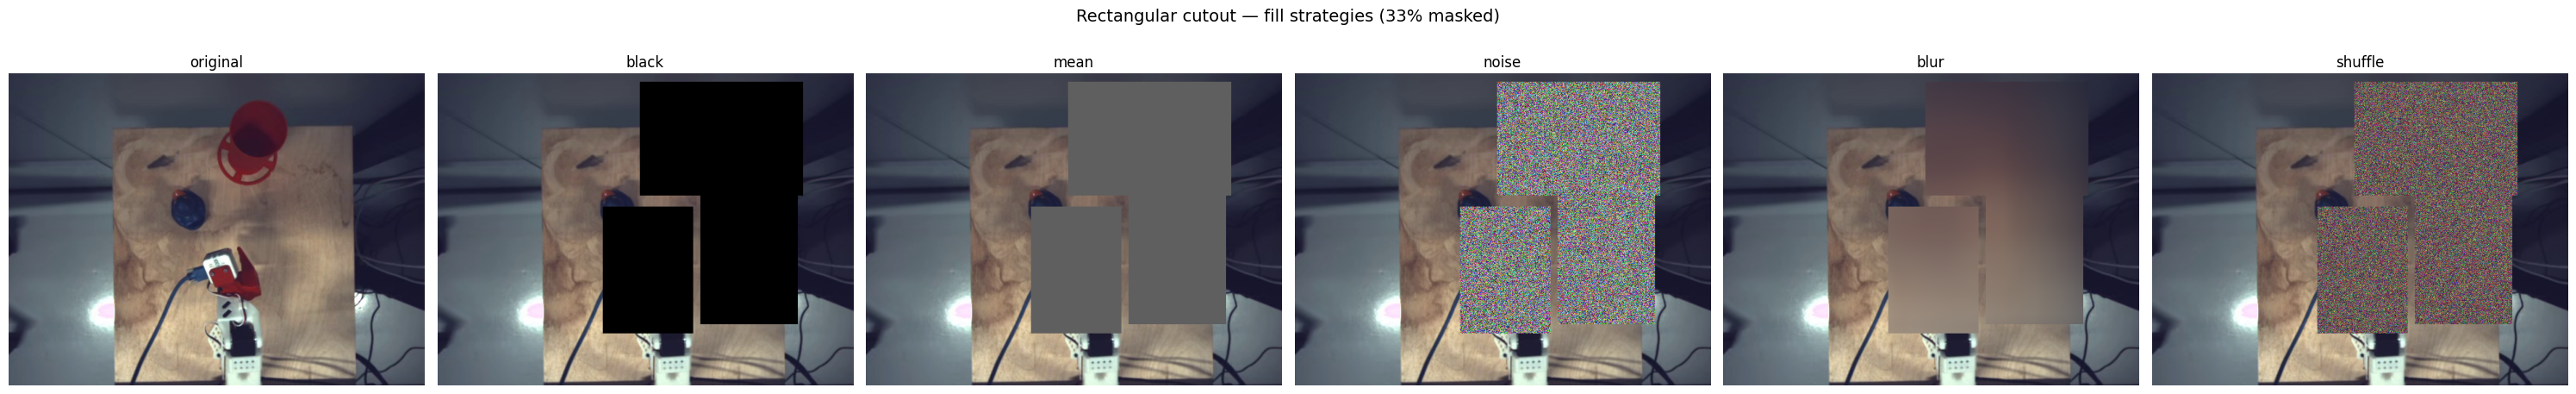

In [6]:
import torch.nn.functional as F

FILL_MODES = ["black", "mean", "noise", "blur", "shuffle"]


def _apply_fill(img: torch.Tensor, out: torch.Tensor, mask: torch.Tensor,
                fill: str, blur_kernel: int = 51):
    """Apply fill strategy to masked pixels. Shared by all mask shapes.

    Args:
        img: (C, H, W) original image
        out: (C, H, W) clone to modify in-place
        mask: (H, W) bool tensor — True = masked pixel
        fill: "black", "mean", "noise", "blur", "shuffle"
        blur_kernel: kernel size for blur fill
    """
    C = img.shape[0]
    if fill == "black":
        out[:, mask] = 0.0
    elif fill == "mean":
        out[:, mask] = img.mean()
    elif fill == "noise":
        n = mask.sum().item()
        out[:, mask] = torch.rand(C, n)
    elif fill == "blur":
        k = blur_kernel if blur_kernel % 2 == 1 else blur_kernel + 1
        padded = F.pad(img.unsqueeze(0), [k//2]*4, mode="reflect")
        blurred = F.avg_pool2d(padded, kernel_size=k, stride=1)[0]
        out[:, mask] = blurred[:, mask]
    elif fill == "shuffle":
        for c in range(C):
            vals = out[c, mask].clone()
            out[c, mask] = vals[torch.randperm(len(vals))]


def mask_rectangular_cutout(
    img: torch.Tensor,
    n_patches: int = 3,
    patch_scale: tuple[float, float] = (0.05, 0.15),
    fill: str = "black",
    blur_kernel: int = 51,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Random rectangular cutout with configurable fill.

    Returns: (masked_img, binary_mask) — mask is (H, W) float
    """
    C, H, W = img.shape
    out = img.clone()
    combined_mask = torch.zeros(H, W, dtype=torch.bool)

    for _ in range(n_patches):
        scale = torch.empty(1).uniform_(*patch_scale).item()
        area = H * W * scale
        aspect = torch.empty(1).uniform_(0.5, 2.0).item()
        ph = int(min((area * aspect) ** 0.5, H))
        pw = int(min((area / aspect) ** 0.5, W))
        y = torch.randint(0, max(H - ph, 1), (1,)).item()
        x = torch.randint(0, max(W - pw, 1), (1,)).item()
        combined_mask[y:y+ph, x:x+pw] = True

    _apply_fill(img, out, combined_mask, fill, blur_kernel)
    return out, combined_mask.float()


# --- Demo: rectangular cutout, all fills ---
sample = dataset[0]
img = sample["observation.images.top"]

results = {"original": img}
for f in FILL_MODES:
    torch.manual_seed(42)
    masked, binary = mask_rectangular_cutout(img, n_patches=3, fill=f, blur_kernel=200)
    results[f] = masked

pct = binary.mean().item() * 100
show_images(results, f"Rectangular cutout — fill strategies ({pct:.0f}% masked)")

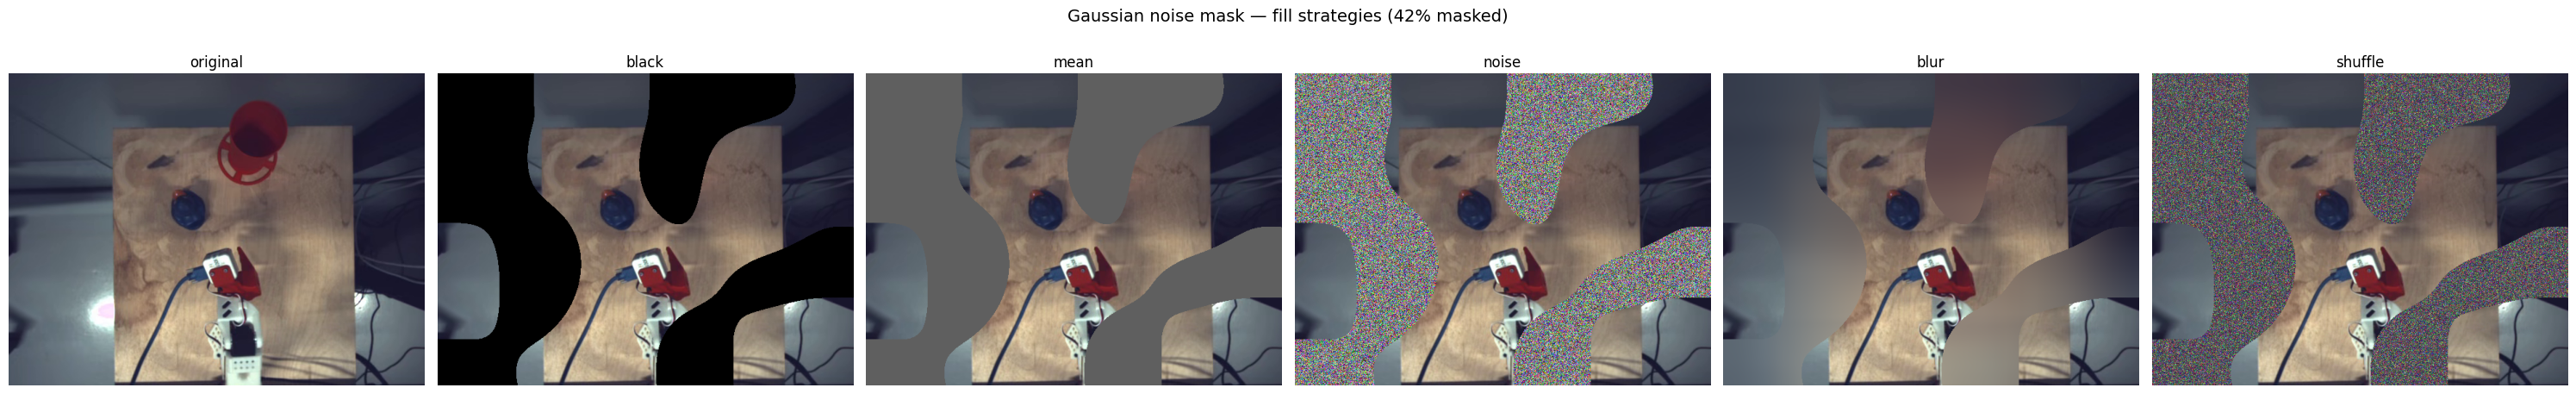

In [7]:
def _generate_mask_field(H: int, W: int, scale: float = 110.0, threshold: float = 0.55) -> torch.Tensor:
    """Generate binary mask from thresholded upscaled Gaussian noise. Returns (H, W) bool."""
    noise_h = max(int(H / scale), 2)
    noise_w = max(int(W / scale), 2)
    small_noise = torch.randn(1, 1, noise_h, noise_w)
    field = torch.nn.functional.interpolate(
        small_noise, size=(H, W), mode="bicubic", align_corners=False
    )[0, 0]
    field = (field - field.min()) / (field.max() - field.min() + 1e-8)
    return field > threshold


def mask_gaussian_noise(
    img: torch.Tensor,
    scale: float = 110.0,
    threshold: float = 0.55,
    fill: str = "black",
    blur_kernel: int = 51,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Mask image regions selected by thresholded Gaussian noise field.

    Returns: (masked_img, binary_mask) — mask is (H, W) float
    """
    C, H, W = img.shape
    binary_mask = _generate_mask_field(H, W, scale, threshold)
    out = img.clone()
    _apply_fill(img, out, binary_mask, fill, blur_kernel)
    return out, binary_mask.float()


# --- Demo: Gaussian noise, all fills ---
sample = dataset[0]
img = sample["observation.images.top"]

results = {"original": img}
for f in FILL_MODES:
    torch.manual_seed(33)
    masked, binary = mask_gaussian_noise(img, scale=100, threshold=0.6, fill=f, blur_kernel=200)
    results[f] = masked

pct = binary.mean().item() * 100
show_images(results, f"Gaussian noise mask — fill strategies ({pct:.0f}% masked)")

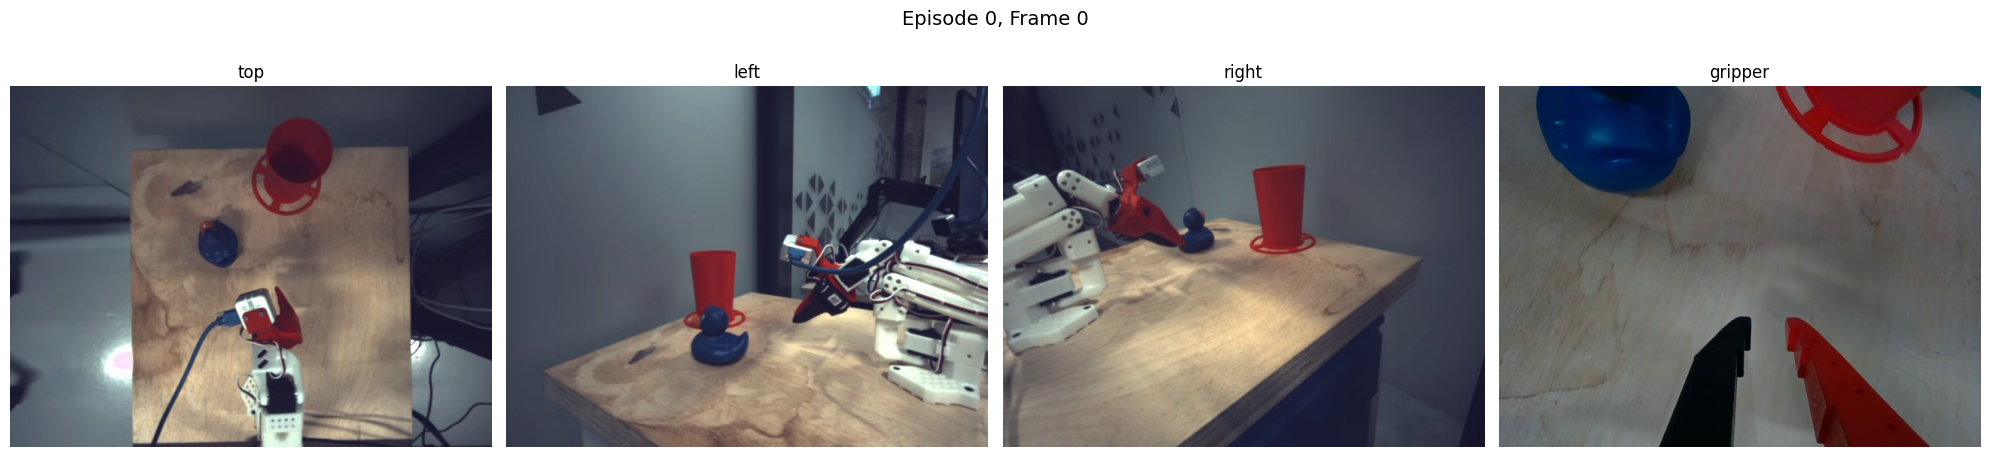

In [8]:
# Test it
imgs = {cam: sample[f"observation.images.{cam}"] for cam in CAMERAS}
show_images(imgs, "Episode 0, Frame 0")

In [ ]:
torch.manual_seed(33)

imgs = {cam: mask_gaussian_noise(sample[f"observation.images.{cam}"], scale=100, threshold=0.6, fill="blur", blur_kernel=200)[0] for cam in CAMERAS}
show_images(imgs, "Episode 0, Frame 0")

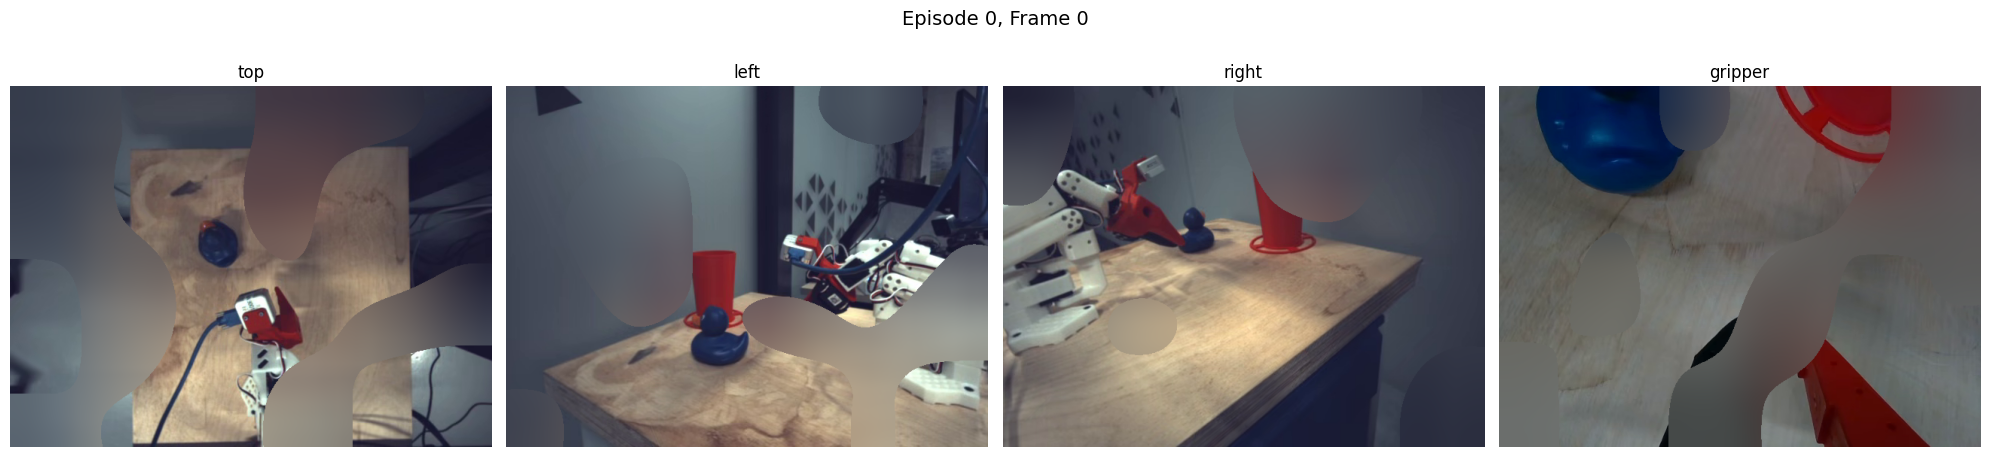

In [13]:
torch.manual_seed(33)

imgs = {cam: mask_gaussian_noise(sample[f"observation.images.{cam}"], scale=100, threshold=0.6, fill="blur", blur_kernel=200)[0] for cam in CAMERAS}
show_images(imgs, "Episode 0, Frame 0")

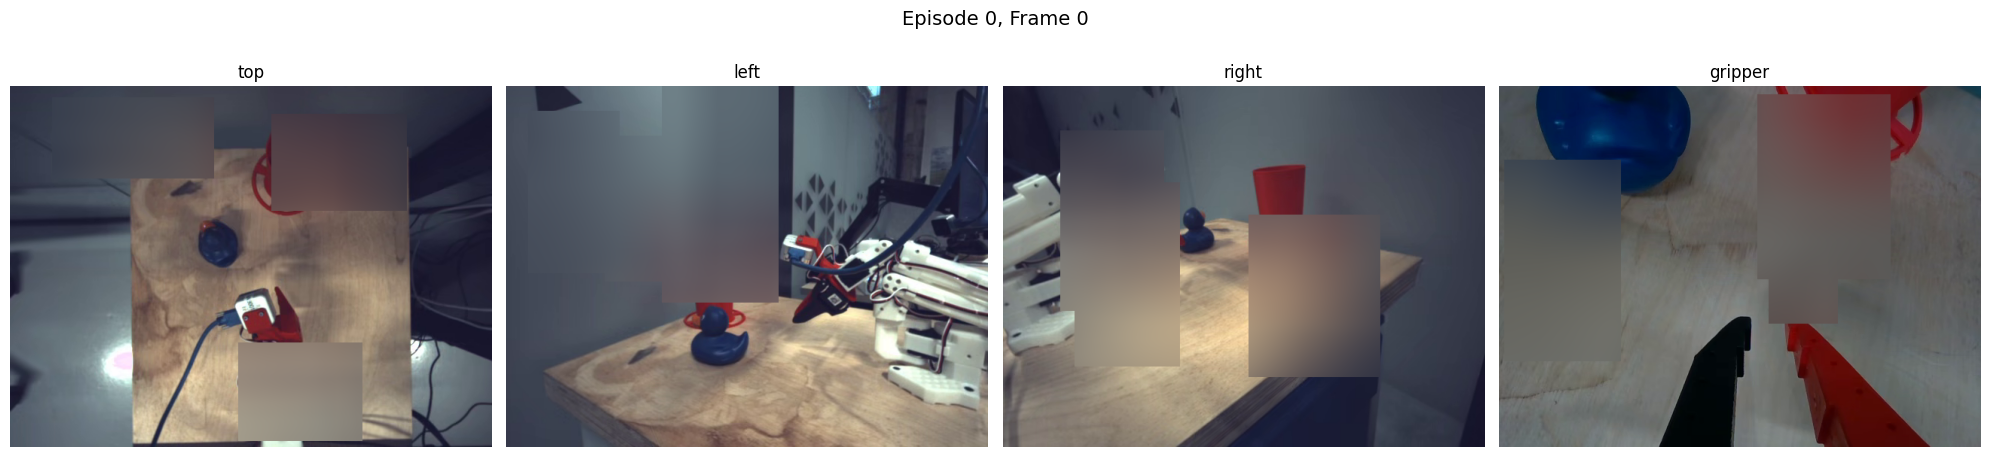

In [17]:
torch.manual_seed(35)

imgs = {cam: mask_rectangular_cutout(sample[f"observation.images.{cam}"], n_patches=3, fill="blur", blur_kernel=200)[0] for cam in CAMERAS}
show_images(imgs, "Episode 0, Frame 0")

#### Load SigLIP encoder

SmolVLA uses `google/siglip-so400m-patch14-384` via SmolVLM. We load just the vision tower directly — same encoder, no need to load the full VLA.

Output: **49 patch tokens × 1152 dims** per image (7×7 grid, patch_size=32). We mean-pool to get a single 1152-d vector for UMAP.

In [4]:
from transformers import SiglipVisionModel, SiglipImageProcessor

SIGLIP_ID = "google/siglip-so400m-patch14-384"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vision_model = SiglipVisionModel.from_pretrained(SIGLIP_ID).to(device).eval()
processor = SiglipImageProcessor.from_pretrained(SIGLIP_ID)

print(f"SigLIP loaded on {device}")
print(f"  Input size: {processor.size}")
print(f"  Hidden dim: {vision_model.config.hidden_size}")
print(f"  Params: {sum(p.numel() for p in vision_model.parameters()):,}")

SigLIP loaded on cuda
  Input size: {'height': 384, 'width': 384}
  Hidden dim: 1152
  Params: 428,225,600


In [7]:
from PIL import Image
from tqdm.auto import tqdm
from __future__ import annotations

def _img_to_pil(img: torch.Tensor) -> Image.Image:
    """(C,H,W) float [0,1] → PIL RGB"""
    return Image.fromarray((img.permute(1, 2, 0).clamp(0, 1).numpy() * 255).astype(np.uint8))


@torch.no_grad()
def get_embeddings_batch(imgs: list[torch.Tensor], batch_size: int = 64) -> np.ndarray:
    """Batch-embed a list of (C,H,W) tensors. Returns (N, 1152) numpy array."""
    all_embs = []
    for i in tqdm(range(0, len(imgs), batch_size), desc="Embedding batches"):
        batch_pils = [_img_to_pil(img) for img in imgs[i:i+batch_size]]
        inputs = processor(images=batch_pils, return_tensors="pt").to(device)
        outputs = vision_model(**inputs)
        embs = outputs.last_hidden_state.mean(dim=1).cpu().numpy()
        all_embs.append(embs)
    return np.concatenate(all_embs, axis=0)


# Quick sanity check
sample = dataset[300]
img = sample["observation.images.top"]
torch.manual_seed(42)
img_masked, _ = mask_gaussian_noise(img, fill="blur")

embs = get_embeddings_batch([img, img_masked])
cos = np.dot(embs[0], embs[1]) / (np.linalg.norm(embs[0]) * np.linalg.norm(embs[1]))
print(f"Batch sanity check — cos_sim: {cos:.4f} (should be ~0.92)")

Embedding batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batch sanity check — cos_sim: 0.9211 (should be ~0.92)


### Exp 2 — UMAP / Distribution Analysis

- UMAP of clean vs masked embeddings — are they on the same manifold?
- Cosine similarity distribution: clean↔clean vs clean↔masked
- Per-camera comparison — which cameras drift most under masking?
- If masked embeddings form a separate cluster → OOD, bad for training
- If they overlap with clean → safe to blend

In [ ]:
from tqdm.auto import tqdm
from pathlib import Path
import gc

# --- Config ---
N_MASKED = 100
BLUR_K = 51
MASK_SEED = 42

SHAPES = {
    "gaussian_noise": lambda img, fill, bk: mask_gaussian_noise(img, scale=100, threshold=0.6, fill=fill, blur_kernel=bk)[0],
    "rectangular_cutout": lambda img, fill, bk: mask_rectangular_cutout(img, n_patches=3, fill=fill, blur_kernel=bk)[0],
}
FILLS = ["black", "mean", "noise", "blur", "shuffle"]

# --- Load cached frames ---
_p1 = Path("cached_frames/frames.pt")
_p2 = Path("vbti/research/how_to_mask_right/cached_frames/frames.pt")
cache_path = _p1 if _p1.exists() else _p2

cache = torch.load(cache_path, weights_only=False)
cached_frames = cache["frames"]
cameras = cache["cameras"]
print(f"Loaded {len(cached_frames)} cached frames, cameras: {cameras}")

# All cached frames → clean embeddings
all_frame_keys = sorted(cached_frames.keys())

# Subsample evenly for masked frames
step = max(len(all_frame_keys) // N_MASKED, 1)
masked_keys = all_frame_keys[::step][:N_MASKED]
print(f"Clean frames: {len(all_frame_keys)}, Masked frames: {len(masked_keys)}")
print(f"Conditions: {len(SHAPES)} shapes x {len(FILLS)} fills = {len(SHAPES) * len(FILLS)} per frame per camera")

# --- Collect all images + metadata ---
all_imgs = []
metadata = []  # parallel list: {frame_idx, camera, condition}

# 1) Clean embeddings — ALL cached frames
for fi in tqdm(all_frame_keys, desc="Loading clean frames"):
    cam_dict = cached_frames[fi]
    for cam in cameras:
        all_imgs.append(cam_dict[cam])
        metadata.append({"frame_idx": fi, "camera": cam, "condition": "clean"})

# 2) Masked embeddings — subset, all shape x fill combos
for fi in tqdm(masked_keys, desc="Applying masks"):
    cam_dict = cached_frames[fi]
    for cam_idx, cam in enumerate(cameras):
        img = cam_dict[cam]
        for shape_name, shape_fn in SHAPES.items():
            for fill in FILLS:
                torch.manual_seed(MASK_SEED + fi + cam_idx)
                masked_img = shape_fn(img, fill, BLUR_K)
                all_imgs.append(masked_img)
                metadata.append({
                    "frame_idx": fi,
                    "camera": cam,
                    "condition": f"{shape_name}_{fill}",
                })

print(f"Collected {len(all_imgs)} images, embedding in batches...")

# --- Batch embed ---
all_embs = get_embeddings_batch(all_imgs, batch_size=64)

# --- Compute cosine similarities (each masked vs its corresponding clean) ---
# Build lookup: (frame_idx, camera) → index of clean embedding
clean_lookup = {}
for i, m in enumerate(metadata):
    if m["condition"] == "clean":
        clean_lookup[(m["frame_idx"], m["camera"])] = i

records = []
for i, m in enumerate(metadata):
    emb = all_embs[i]
    if m["condition"] == "clean":
        cos = 1.0
    else:
        clean_idx = clean_lookup[(m["frame_idx"], m["camera"])]
        clean_emb = all_embs[clean_idx]
        cos = float(np.dot(clean_emb, emb) / (np.linalg.norm(clean_emb) * np.linalg.norm(emb) + 1e-8))
    records.append({
        "frame_idx": m["frame_idx"],
        "camera": m["camera"],
        "condition": m["condition"],
        "embedding": emb,
        "cos_sim": cos,
    })

# --- Cleanup ---
del cache, all_imgs, metadata
gc.collect()

# --- Summary ---
print(f"\nTotal records: {len(records)}")
print(f"\nMean cosine similarity per condition:")
from collections import defaultdict
cond_sims = defaultdict(list)
for r in records:
    if r["condition"] != "clean":
        cond_sims[r["condition"]].append(r["cos_sim"])
for cond in sorted(cond_sims.keys()):
    sims = cond_sims[cond]
    print(f"  {cond:35s}  mean={np.mean(sims):.4f}  std={np.std(sims):.4f}  n={len(sims)}")

Loaded 582 cached frames, cameras: ['top', 'left', 'right', 'gripper']
Clean frames: 582, Masked frames: 100
Conditions: 2 shapes x 5 fills = 10 per frame per camera


Loading clean frames:   0%|          | 0/582 [00:00<?, ?it/s]

Applying masks:   0%|          | 0/100 [00:00<?, ?it/s]

In [ ]:
# cleanup done in processing cell above
import gc; gc.collect()
print(f"Records: {len(records)}, cached_frames: {len(cached_frames)} frames kept for viz")

In [ ]:
import umap
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px

# --- UMAP: one subplot per camera ---
all_embs_umap = np.array([r["embedding"] for r in records])

# Fit UMAP on ALL embeddings jointly so positions are comparable
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42)
coords_2d = reducer.fit_transform(all_embs_umap)

for i, r in enumerate(records):
    r["umap_x"] = coords_2d[i, 0]
    r["umap_y"] = coords_2d[i, 1]

# --- Color map: 10 distinct colors for masked conditions ---
all_conditions = sorted(set(r["condition"] for r in records if r["condition"] != "clean"))
palette = px.colors.qualitative.T10  # 10-color palette
color_map = {cond: palette[i % len(palette)] for i, cond in enumerate(all_conditions)}

n_clean = sum(1 for r in records if r["condition"] == "clean")
n_masked = sum(1 for r in records if r["condition"] != "clean")

# --- Build plotly figure: 1 row x 4 cameras ---
fig = make_subplots(rows=1, cols=4, subplot_titles=CAMERAS, horizontal_spacing=0.04)

for col_idx, cam in enumerate(CAMERAS, 1):
    cam_records = [r for r in records if r["camera"] == cam]

    # Clean points as grey background
    clean_recs = [r for r in cam_records if r["condition"] == "clean"]
    fig.add_trace(go.Scatter(
        x=[r["umap_x"] for r in clean_recs],
        y=[r["umap_y"] for r in clean_recs],
        mode="markers",
        marker=dict(size=3, color="grey", opacity=0.3),
        name="clean",
        text=[f"frame={r['frame_idx']}<br>condition=clean<br>cos_sim=1.000" for r in clean_recs],
        hovertemplate="%{text}<extra>clean</extra>",
        legendgroup="clean",
        showlegend=(col_idx == 1),
    ), row=1, col=col_idx)

    # Masked conditions with distinct colors
    for cond in all_conditions:
        cond_recs = [r for r in cam_records if r["condition"] == cond]
        if not cond_recs:
            continue
        fig.add_trace(go.Scatter(
            x=[r["umap_x"] for r in cond_recs],
            y=[r["umap_y"] for r in cond_recs],
            mode="markers",
            marker=dict(size=4, color=color_map[cond], opacity=0.7),
            name=cond,
            text=[
                f"frame={r['frame_idx']}<br>condition={r['condition']}<br>cos_sim={r['cos_sim']:.3f}"
                for r in cond_recs
            ],
            hovertemplate="%{text}<extra>%{fullData.name}</extra>",
            legendgroup=cond,
            showlegend=(col_idx == 1),
        ), row=1, col=col_idx)

fig.update_layout(
    title=f"UMAP — {len(all_conditions)} masked conditions vs {n_clean} clean frames (N_MASKED={n_masked})",
    height=600, width=1800,
    legend=dict(orientation="h", yanchor="bottom", y=1.05),
)
fig.update_xaxes(showticklabels=False)
fig.update_yaxes(showticklabels=False)
fig.show()

In [ ]:
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import rbf_kernel

# ============================================================
# 1. Cosine similarity violin plot — one subplot per camera
# ============================================================
masked_records = [r for r in records if r["condition"] != "clean"]
all_conditions = sorted(set(r["condition"] for r in masked_records))
palette = px.colors.qualitative.T10
color_map = {cond: palette[i % len(palette)] for i, cond in enumerate(all_conditions)}

fig_violin = make_subplots(rows=1, cols=4, subplot_titles=CAMERAS, horizontal_spacing=0.06)

for col_idx, cam in enumerate(CAMERAS, 1):
    cam_masked = [r for r in masked_records if r["camera"] == cam]
    for cond in all_conditions:
        cond_recs = [r for r in cam_masked if r["condition"] == cond]
        if not cond_recs:
            continue
        fig_violin.add_trace(go.Violin(
            x=[cond] * len(cond_recs),
            y=[r["cos_sim"] for r in cond_recs],
            name=cond,
            legendgroup=cond,
            showlegend=(col_idx == 1),
            line_color=color_map[cond],
            spanmode="hard",
            meanline_visible=True,
        ), row=1, col=col_idx)

fig_violin.update_layout(
    title="Cosine Similarity Distribution per Condition per Camera",
    height=600, width=1800,
    legend=dict(orientation="h", yanchor="bottom", y=1.05),
    violinmode="overlay",
)
fig_violin.update_xaxes(tickangle=45, tickfont=dict(size=8))
fig_violin.update_yaxes(title_text="cos_sim", col=1)
fig_violin.show()

# ============================================================
# 2. Summary table — median, IQR, min per condition per camera
# ============================================================
print("\n" + "=" * 100)
print(f"{'CONDITION':<35s}", end="")
for cam in CAMERAS:
    print(f"  {cam:>12s} (med/IQR/min)", end="")
print()
print("=" * 100)

for cond in all_conditions:
    print(f"{cond:<35s}", end="")
    for cam in CAMERAS:
        sims = np.array([r["cos_sim"] for r in masked_records
                         if r["condition"] == cond and r["camera"] == cam])
        if len(sims) == 0:
            print(f"  {'n/a':>30s}", end="")
        else:
            med = np.median(sims)
            q25, q75 = np.percentile(sims, [25, 75])
            iqr = q75 - q25
            mn = sims.min()
            print(f"  {med:6.4f} / {iqr:5.4f} / {mn:6.4f}", end="")
    print()

# ============================================================
# 3. k-NN intrusion rate
# ============================================================
K = 10

# Organize embeddings per camera
knn_results = {}  # {(cond, cam): fraction of clean neighbors}

for cam in CAMERAS:
    # Get all embeddings for this camera
    cam_recs = [r for r in records if r["camera"] == cam]
    cam_embs = np.array([r["embedding"] for r in cam_recs])
    cam_conds = [r["condition"] for r in cam_recs]
    is_clean = np.array([c == "clean" for c in cam_conds])

    # Fit k-NN on all embeddings for this camera
    nn = NearestNeighbors(n_neighbors=K + 1, metric="cosine", algorithm="brute")
    nn.fit(cam_embs)

    # For each masked embedding, find neighbors
    masked_indices = [i for i, c in enumerate(cam_conds) if c != "clean"]
    if not masked_indices:
        continue

    distances, neighbors = nn.kneighbors(cam_embs[masked_indices])

    for local_idx, global_idx in enumerate(masked_indices):
        cond = cam_conds[global_idx]
        # Exclude self from neighbors
        neigh_idx = neighbors[local_idx]
        neigh_idx = neigh_idx[neigh_idx != global_idx][:K]
        frac_clean = is_clean[neigh_idx].mean()
        knn_results.setdefault((cond, cam), []).append(frac_clean)

# Build heatmap data
knn_matrix = np.zeros((len(all_conditions), len(CAMERAS)))
for i, cond in enumerate(all_conditions):
    for j, cam in enumerate(CAMERAS):
        vals = knn_results.get((cond, cam), [])
        knn_matrix[i, j] = np.mean(vals) if vals else 0.0

# ============================================================
# 4. MMD (Maximum Mean Discrepancy) with RBF kernel
# ============================================================
# Estimate median pairwise distance for bandwidth selection
sample_embs = np.array([r["embedding"] for r in records])
subsample = sample_embs[np.random.choice(len(sample_embs), min(500, len(sample_embs)), replace=False)]
from scipy.spatial.distance import pdist
median_dist = np.median(pdist(subsample, metric="euclidean"))
gamma = 1.0 / (2 * median_dist ** 2) if median_dist > 0 else 1.0

mmd_matrix = np.zeros((len(all_conditions), len(CAMERAS)))

for j, cam in enumerate(CAMERAS):
    clean_embs_cam = np.array([r["embedding"] for r in records
                               if r["camera"] == cam and r["condition"] == "clean"])
    for i, cond in enumerate(all_conditions):
        masked_embs_cam = np.array([r["embedding"] for r in records
                                    if r["camera"] == cam and r["condition"] == cond])
        if len(masked_embs_cam) == 0 or len(clean_embs_cam) == 0:
            mmd_matrix[i, j] = 0.0
            continue
        Kxx = rbf_kernel(clean_embs_cam, clean_embs_cam, gamma=gamma)
        Kyy = rbf_kernel(masked_embs_cam, masked_embs_cam, gamma=gamma)
        Kxy = rbf_kernel(clean_embs_cam, masked_embs_cam, gamma=gamma)
        mmd2 = Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()
        mmd_matrix[i, j] = max(mmd2, 0.0) ** 0.5  # MMD (not squared)

# --- Plot both heatmaps side by side ---
fig_heat = make_subplots(rows=1, cols=2, subplot_titles=["k-NN Clean Intrusion Rate (k=10)", "MMD (RBF kernel)"],
                         horizontal_spacing=0.12)

fig_heat.add_trace(go.Heatmap(
    z=knn_matrix, x=CAMERAS, y=all_conditions,
    colorscale="Greens", zmin=0, zmax=1,
    text=np.round(knn_matrix, 3).astype(str), texttemplate="%{text}",
    colorbar=dict(x=0.45, len=0.9),
), row=1, col=1)

fig_heat.add_trace(go.Heatmap(
    z=mmd_matrix, x=CAMERAS, y=all_conditions,
    colorscale="Reds",
    text=np.round(mmd_matrix, 4).astype(str), texttemplate="%{text}",
    colorbar=dict(x=1.0, len=0.9),
), row=1, col=2)

fig_heat.update_layout(height=500, width=1200, title="Distribution Metrics: k-NN Intrusion + MMD")
fig_heat.show()

# ============================================================
# inspect_frame and show_masked — fixed seed: MASK_SEED + fi + cam_idx
# ============================================================

def inspect_frame(fi: int, cam: str = None):
    """Show clean vs a subset of masked versions for a frame, with cosine sim."""
    if fi not in cached_frames:
        print(f"Frame {fi} not in cache. Available: {sorted(cached_frames.keys())[:5]}...")
        return

    cams = [cam] if cam else CAMERAS
    # Show a representative subset: one fill per shape
    demo_conditions = [("clean", None, None)]
    for shape_name, shape_fn in SHAPES.items():
        for fill in FILLS:
            demo_conditions.append((f"{shape_name}_{fill}", shape_fn, fill))

    n_conds = len(demo_conditions)
    fig, axes = plt.subplots(len(cams), n_conds, figsize=(3 * n_conds, 3 * len(cams)))
    if len(cams) == 1:
        axes = [axes]
    if n_conds == 1:
        axes = [[ax] for ax in axes]

    frame_records = {(r["camera"], r["condition"]): r for r in records if r["frame_idx"] == fi}

    for row, c in enumerate(cams):
        cam_idx = CAMERAS.index(c)
        img = cached_frames[fi][c]
        for col, (cond_name, shape_fn, fill) in enumerate(demo_conditions):
            ax = axes[row][col]
            if shape_fn is None:
                display_img = img
            else:
                torch.manual_seed(MASK_SEED + fi + cam_idx)
                display_img = shape_fn(img, fill, BLUR_K)
            ax.imshow(display_img.permute(1, 2, 0).clamp(0, 1).numpy())
            r = frame_records.get((c, cond_name))
            cos = f"cos={r['cos_sim']:.3f}" if r and cond_name != "clean" else ""
            ax.set_title(f"{c}/{cond_name}\n{cos}", fontsize=7)
            ax.axis("off")

    plt.suptitle(f"Frame {fi} — all conditions", fontsize=12)
    plt.tight_layout()
    plt.show()


def show_masked(fi: int, shape: str = "gaussian_noise", fill: str = "blur"):
    """Show all 4 cameras masked for a given frame."""
    if fi not in cached_frames:
        print(f"Frame {fi} not in cache")
        return

    shape_fn = SHAPES.get(shape)
    if shape_fn is None:
        print(f"Unknown shape: {shape}. Available: {list(SHAPES.keys())}")
        return

    clean = {}
    masked = {}
    for cam in CAMERAS:
        cam_idx = CAMERAS.index(cam)
        img = cached_frames[fi][cam]
        clean[cam] = img
        torch.manual_seed(MASK_SEED + fi + cam_idx)
        masked[cam] = shape_fn(img, fill, BLUR_K)

    show_images(clean, f"Frame {fi} — clean")
    show_images(masked, f"Frame {fi} — {shape} / {fill}")

In [ ]:
def show_masked(fi: int, shape: str = "gaussian_noise", fill: str = "mean"):
    """Show all 4 cameras masked for a given frame."""
    if fi not in cached_frames:
        print(f"Frame {fi} not in cache")
        return
    clean = {}
    masked = {}
    for cam_idx, cam in enumerate(CAMERAS):
        img = cached_frames[fi][cam]
        clean[cam] = img
        torch.manual_seed(MASK_SEED + fi + cam_idx)
        if "gaussian" in shape:
            m, _ = mask_gaussian_noise(img, scale=100, threshold=0.6, fill=fill, blur_kernel=BLUR_K)
        else:
            m, _ = mask_rectangular_cutout(img, n_patches=3, fill=fill, blur_kernel=BLUR_K)
        masked[cam] = m
    show_images(clean, f"Frame {fi} — clean")
    show_images(masked, f"Frame {fi} — {shape} / {fill}")


def inspect_frame(fi: int, cam: str = None):
    """Show clean vs all masked versions for a frame, with cosine sim."""
    if fi not in cached_frames:
        print(f"Frame {fi} not in cache")
        return
    cams = [cam] if cam else CAMERAS
    frame_records = {(r["camera"], r["condition"]): r for r in records if r["frame_idx"] == fi}
    conditions = ["clean"] + sorted(set(r["condition"] for r in records if r["condition"] != "clean"))
    
    fig, axes = plt.subplots(len(cams), min(len(conditions), 6), figsize=(4 * min(len(conditions), 6), 4 * len(cams)))
    if len(cams) == 1: axes = [axes]
    if min(len(conditions), 6) == 1: axes = [[ax] for ax in axes]
    
    for row, c in enumerate(cams):
        cam_idx = CAMERAS.index(c)
        img = cached_frames[fi][c]
        for col, cond in enumerate(conditions[:6]):
            if cond == "clean":
                display_img = img
            else:
                shape, fill = cond.rsplit("_", 1)
                torch.manual_seed(MASK_SEED + fi + cam_idx)
                if "gaussian" in shape:
                    display_img, _ = mask_gaussian_noise(img, scale=100, threshold=0.6, fill=fill, blur_kernel=BLUR_K)
                else:
                    display_img, _ = mask_rectangular_cutout(img, n_patches=3, fill=fill, blur_kernel=BLUR_K)
            axes[row][col].imshow(display_img.permute(1, 2, 0).clamp(0, 1).numpy())
            r = frame_records.get((c, cond))
            cos = f"cos={r["cos_sim"]:.3f}" if r and cond != "clean" else ""
            axes[row][col].set_title(f"{cond}{cos}", fontsize=8)
            axes[row][col].axis("off")
    plt.suptitle(f"Frame {fi}", fontsize=14)
    plt.tight_layout()
    plt.show()


### Exp 3 — Feature Attribution

- Which embedding dimensions activate for cup vs duck?
- Compute feature difference: embeddings(cup at pos A) - embeddings(cup at pos B) with same duck
- Compare to: embeddings(duck at pos A) - embeddings(duck at pos B) with same cup
- Does masking selectively suppress the cup-sensitive dimensions?
